# Bias vs variance with LDA and QDA

LDA assumes every class shares the same variance (σ_k = σ). That assumption deletes the quadratic terms from the discriminant and gives a linear boundary. If the assumption is true, nothing is lost. If the true variances differ, the shared σ introduces **bias**. Either way, LDA estimates far fewer parameters, which means **lower variance**.

This notebook shows both sides with simulations:

1. **1D example.** The true boundary has two thresholds, LDA can only draw one. That bias doesn't go away with more data.
2. **10D example.** QDA has to estimate a full covariance matrix per class. With little data LDA wins, with more data QDA wins.
3. **Control.** Same 10D setup with equal variances. The assumption holds, LDA has no bias, and it wins at every size.

Everything runs in a few seconds on Colab.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
import warnings; warnings.filterwarnings("ignore")

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. One feature, unequal variances

Class 0 ~ N(0, 1²) and class 1 ~ N(2, 2²), equal priors. Because class 1 is wider, it wins in **both** tails, so the Bayes rule has two thresholds.

In [2]:
MU, SD, PI = np.array([0.0, 2.0]), np.array([1.0, 2.0]), np.array([0.5, 0.5])

def sample_1d(n):
    y = rng.integers(0, 2, n)
    x = rng.normal(MU[y], SD[y])
    return x[:, None], y

grid = np.linspace(-6, 10, 4001)

def bayes_pred(x):
    s = [np.log(PI[k]) + norm.logpdf(x, MU[k], SD[k]) for k in (0, 1)]
    return (s[1] > s[0]).astype(int)

def thresholds(pred):
    """Points on the grid where the predicted class flips."""
    idx = np.where(np.diff(pred) != 0)[0]
    return grid[idx]

bayes_t = thresholds(bayes_pred(grid))
X_test, y_test = sample_1d(200_000)
bayes_err = np.mean(bayes_pred(X_test[:, 0]) != y_test)
print("Bayes thresholds:", np.round(bayes_t, 3))
print(f"Bayes error rate: {bayes_err:.3f}")

Bayes thresholds: [-2.572  1.236]
Bayes error rate: 0.227


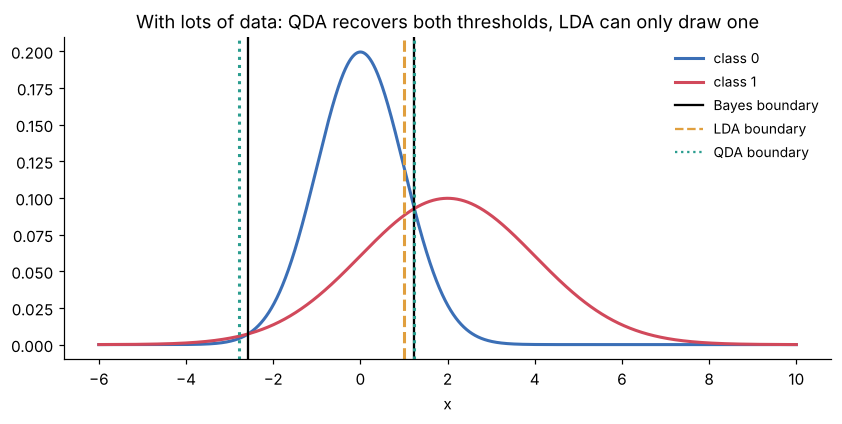

In [3]:
X, y = sample_1d(5000)
lda_t = thresholds(LDA().fit(X, y).predict(grid[:, None]))
qda_t = thresholds(QDA().fit(X, y).predict(grid[:, None]))

fig, ax = plt.subplots(figsize=(9, 3.8))
for k, c in zip((0, 1), ("#3b6fb6", "#d1495b")):
    ax.plot(grid, PI[k] * norm.pdf(grid, MU[k], SD[k]), color=c, lw=2, label=f"class {k}")
for t in bayes_t: ax.axvline(t, color="black", lw=1.5, ls="-")
for t in lda_t:   ax.axvline(t, color="#e09f3e", lw=2, ls="--")
for t in qda_t:   ax.axvline(t, color="#2a9d8f", lw=2, ls=":")
ax.plot([], [], color="black", label="Bayes boundary")
ax.plot([], [], color="#e09f3e", ls="--", label="LDA boundary")
ax.plot([], [], color="#2a9d8f", ls=":", label="QDA boundary")
ax.set_title("With lots of data: QDA recovers both thresholds, LDA can only draw one")
ax.set_xlabel("x"); ax.legend(frameon=False, fontsize=9)
plt.show()

### Test error vs training size in 1D

LDA plateaus above the Bayes error because of its bias. QDA converges to the Bayes error. In 1D QDA only pays for one extra parameter, so the two are close on tiny samples and QDA pulls ahead almost immediately.

In [4]:
sizes_1d = [10, 20, 40, 100, 500, 2000]
Xt, yt = X_test[:20000], y_test[:20000]
print(f"{'n':>6}{'LDA err':>10}{'QDA err':>10}")
for n in sizes_1d:
    el, eq = [], []
    for _ in range(200):
        X, y = sample_1d(n)
        if np.bincount(y, minlength=2).min() < 3: continue
        el.append(1 - LDA().fit(X, y).score(Xt, yt))
        eq.append(1 - QDA().fit(X, y).score(Xt, yt))
    print(f"{n:>6}{np.mean(el):>10.3f}{np.mean(eq):>10.3f}")
print(f"Bayes error: {bayes_err:.3f}")

     n   LDA err   QDA err


    10     0.301     0.290


    20     0.265     0.256


    40     0.253     0.241


   100     0.237     0.230


   500     0.234     0.227


  2000     0.233     0.227
Bayes error: 0.227


## 2. Ten features: where the tradeoff flips

With p features, LDA estimates one shared covariance matrix (p(p+1)/2 = 55 numbers) while QDA estimates one per class (110). Here class 1 has 1.4x the spread of class 0 and a shifted mean, so QDA is the correct model. The question is how much data it needs before that matters.

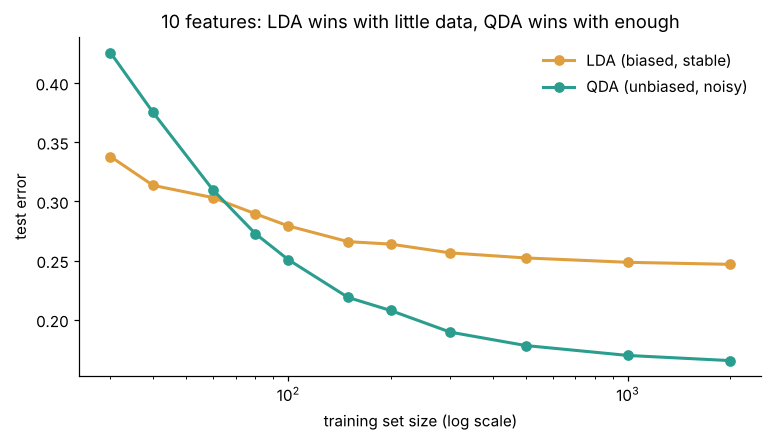

n=   30  LDA=0.338  QDA=0.426  better=LDA
n=   40  LDA=0.313  QDA=0.375  better=LDA
n=   60  LDA=0.303  QDA=0.310  better=LDA
n=   80  LDA=0.290  QDA=0.273  better=QDA
n=  100  LDA=0.279  QDA=0.251  better=QDA
n=  150  LDA=0.266  QDA=0.219  better=QDA
n=  200  LDA=0.264  QDA=0.208  better=QDA
n=  300  LDA=0.256  QDA=0.189  better=QDA
n=  500  LDA=0.252  QDA=0.178  better=QDA
n= 1000  LDA=0.248  QDA=0.170  better=QDA
n= 2000  LDA=0.247  QDA=0.165  better=QDA


In [5]:
P = 10

def sample_p(n):
    y = rng.integers(0, 2, n)
    X = rng.normal(size=(n, P))
    X[y == 1] = X[y == 1] * 1.4 + 0.5
    return X, y

Xt_p, yt_p = sample_p(20000)
sizes = [30, 40, 60, 80, 100, 150, 200, 300, 500, 1000, 2000]
curve = {"LDA": [], "QDA": []}
for n in sizes:
    el, eq = [], []
    for _ in range(100):
        X, y = sample_p(n)
        if np.bincount(y, minlength=2).min() < P + 2: continue
        try:
            q = 1 - QDA().fit(X, y).score(Xt_p, yt_p)
        except np.linalg.LinAlgError:  # QDA can't invert a near-singular covariance on tiny samples
            continue
        el.append(1 - LDA().fit(X, y).score(Xt_p, yt_p)); eq.append(q)
    curve["LDA"].append(np.mean(el)); curve["QDA"].append(np.mean(eq))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sizes, curve["LDA"], "o-", color="#e09f3e", lw=2, label="LDA (biased, stable)")
ax.plot(sizes, curve["QDA"], "o-", color="#2a9d8f", lw=2, label="QDA (unbiased, noisy)")
ax.set_xscale("log"); ax.set_xlabel("training set size (log scale)"); ax.set_ylabel("test error")
ax.set_title("10 features: LDA wins with little data, QDA wins with enough")
ax.legend(frameon=False)
plt.show()

for n, a, b in zip(sizes, curve["LDA"], curve["QDA"]):
    print(f"n={n:>5}  LDA={a:.3f}  QDA={b:.3f}  better={'LDA' if a < b else 'QDA'}")

## 3. Control: when the assumption is true

Same 10D setup, but now both classes have the same covariance (only the mean shifts). Here pooling σ introduces **no bias**, because the x² and log σ_k terms really are identical across classes. LDA keeps its low variance and gives up nothing, so it should win at every sample size.

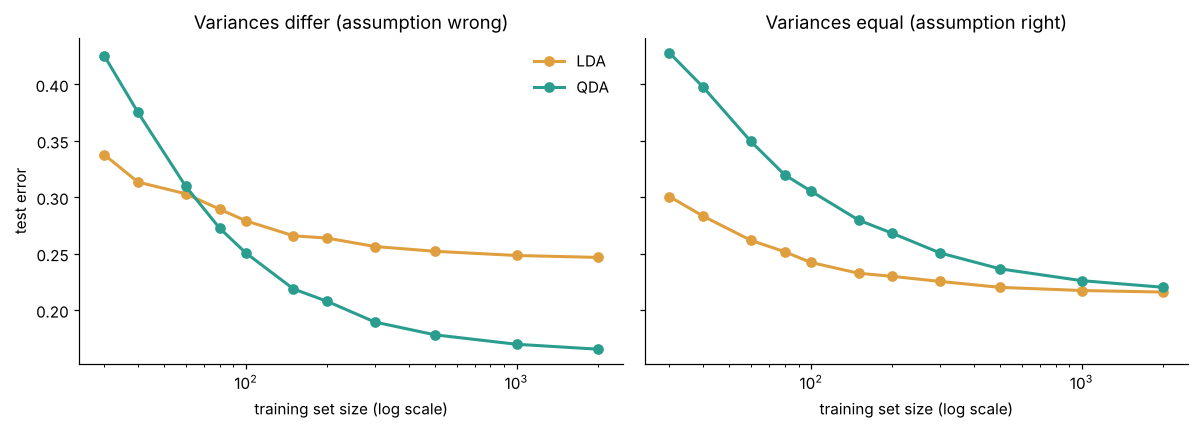

n=   30  LDA=0.301  QDA=0.428  better=LDA
n=   40  LDA=0.283  QDA=0.398  better=LDA
n=   60  LDA=0.262  QDA=0.350  better=LDA
n=   80  LDA=0.252  QDA=0.320  better=LDA
n=  100  LDA=0.242  QDA=0.305  better=LDA
n=  150  LDA=0.233  QDA=0.280  better=LDA
n=  200  LDA=0.230  QDA=0.268  better=LDA
n=  300  LDA=0.225  QDA=0.251  better=LDA
n=  500  LDA=0.220  QDA=0.237  better=LDA
n= 1000  LDA=0.217  QDA=0.226  better=LDA
n= 2000  LDA=0.216  QDA=0.220  better=LDA


In [6]:
def sample_eq(n):
    y = rng.integers(0, 2, n)
    X = rng.normal(size=(n, P))
    X[y == 1] = X[y == 1] + 0.5
    return X, y

Xt_e, yt_e = sample_eq(20000)
curve_eq = {"LDA": [], "QDA": []}
for n in sizes:
    el, eq = [], []
    for _ in range(100):
        X, y = sample_eq(n)
        if np.bincount(y, minlength=2).min() < P + 2: continue
        try:
            q = 1 - QDA().fit(X, y).score(Xt_e, yt_e)
        except np.linalg.LinAlgError:
            continue
        el.append(1 - LDA().fit(X, y).score(Xt_e, yt_e)); eq.append(q)
    curve_eq["LDA"].append(np.mean(el)); curve_eq["QDA"].append(np.mean(eq))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cv, title in [(axes[0], curve, "Variances differ (assumption wrong)"),
                      (axes[1], curve_eq, "Variances equal (assumption right)")]:
    ax.plot(sizes, cv["LDA"], "o-", color="#e09f3e", lw=2, label="LDA")
    ax.plot(sizes, cv["QDA"], "o-", color="#2a9d8f", lw=2, label="QDA")
    ax.set_xscale("log"); ax.set_xlabel("training set size (log scale)"); ax.set_title(title)
axes[0].set_ylabel("test error"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

for n, a, b in zip(sizes, curve_eq["LDA"], curve_eq["QDA"]):
    print(f"n={n:>5}  LDA={a:.3f}  QDA={b:.3f}  better={'LDA' if a < b else 'QDA'}")

## Takeaways

- Dropping σ_k for a shared σ is a modeling assumption. It only introduces bias **if the assumption is wrong**. When the class variances really differ, LDA plateaus above the Bayes error and more data won't fix it. When they're equal, LDA is unbiased and strictly better.
- That same assumption cuts the number of parameters, so LDA is much more stable on small samples.
- Which one wins depends on how much data you have relative to the number of parameters. In 1D QDA's extra cost is tiny, so it wins almost right away. In 10D it takes roughly 70 to 80 samples before QDA's flexibility pays off.
- A middle ground is regularized discriminant analysis, which shrinks each class covariance toward the pooled one: Σ_k(α) = α Σ̂_k + (1 − α) Σ̂, with α chosen by cross-validation.